In [1]:
# Dataset setup:
# Extract your dataset archive manually in Google Colab or place the extracted folder
# at the dataset path used in the following cells.

Archive:  /content/beard.zip
  inflating: Beard or No Beared/Test/Beard/1.jpg  
  inflating: Beard or No Beared/Test/Beard/10.jpg  
  inflating: Beard or No Beared/Test/Beard/2.jpg  
  inflating: Beard or No Beared/Test/Beard/3.jpg  
  inflating: Beard or No Beared/Test/Beard/4.jpg  
  inflating: Beard or No Beared/Test/Beard/5.jpg  
  inflating: Beard or No Beared/Test/Beard/6.jpg  
  inflating: Beard or No Beared/Test/Beard/7.jpg  
  inflating: Beard or No Beared/Test/Beard/8.jpg  
  inflating: Beard or No Beared/Test/Beard/9.jpg  
  inflating: Beard or No Beared/Test/No Beard/1.jpg  
  inflating: Beard or No Beared/Test/No Beard/10.jpg  
  inflating: Beard or No Beared/Test/No Beard/2.jpg  
  inflating: Beard or No Beared/Test/No Beard/3.jpg  
  inflating: Beard or No Beared/Test/No Beard/4.jpg  
  inflating: Beard or No Beared/Test/No Beard/5.jpg  
  inflating: Beard or No Beared/Test/No Beard/6.jpg  
  inflating: Beard or No Beared/Test/No Beard/7.jpg  
  inflating: Beard or No Be

In [2]:
import os
import shutil
import random

original_dataset_dir = "/content/facemask-dataset/dataset"
base_dir = "/content/facemask-dataset/dataset_split"

train_dir = os.path.join(base_dir, "train")
test_dir = os.path.join(base_dir, "test")

# Create folders
for folder in ["train/with_mask", "train/without_mask", "test/with_mask", "test/without_mask"]:
    os.makedirs(os.path.join(base_dir, folder), exist_ok=True)

# Split function
def split_data(class_name, split_size=0.8):
    source_dir = os.path.join(original_dataset_dir, class_name)
    images = os.listdir(source_dir)
    random.seed(42)
    random.shuffle(images)

    split_index = int(len(images) * split_size)

    train_images = images[:split_index]
    test_images = images[split_index:]

    for img in train_images:
        shutil.copy(os.path.join(source_dir, img),
                    os.path.join(train_dir, class_name, img))

    for img in test_images:
        shutil.copy(os.path.join(source_dir, img),
                    os.path.join(test_dir, class_name, img))

# Split both classes
split_data("with_mask")
split_data("without_mask")

print("Dataset split completed!")

FileNotFoundError: [Errno 2] No such file or directory: '/content/facemask-dataset/dataset/with_mask'

In [3]:
import os
train_labels=os.listdir('/content/Beard or No Beared/Train')
test_labels=os.listdir('/content/Beard or No Beared/Test')
print(train_labels)
print(test_labels)

['No Beard', 'Beard']
['No Beard', 'Beard']


In [5]:
import tensorflow as tf
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt

IMG_SIZE = 160
BATCH_SIZE = 32
EPOCHS = 20

train_dir = "/content/Beard or No Beared/Train"
test_dir = "/content/Beard or No Beared/Test"

train_dataset = tf.keras.preprocessing.image_dataset_from_directory(
    train_dir,
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    label_mode="binary"
)

test_dataset = tf.keras.preprocessing.image_dataset_from_directory(
    test_dir,
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    label_mode="binary"
)

model = models.Sequential([
    layers.Rescaling(1./255),

    layers.Conv2D(32, (3,3), activation='relu', input_shape=(IMG_SIZE, IMG_SIZE, 3)),
    layers.MaxPooling2D(2,2),

    layers.Conv2D(64, (3,3), activation='relu'),
    layers.MaxPooling2D(2,2),

    layers.Conv2D(128, (3,3), activation='relu'),
    layers.MaxPooling2D(2,2),

    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),


    layers.Dense(1, activation='sigmoid')
])

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

history = model.fit(
    train_dataset,
    validation_data=test_dataset,
    epochs=EPOCHS
)


Found 119 files belonging to 2 classes.
Found 20 files belonging to 2 classes.
Epoch 1/20


/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


4/4 ━━━━━━━━━━━━━━━━━━━━ 11s 1s/step - accuracy: 0.5180 - loss: 0.7313 - val_accuracy: 0.5000 - val_loss: 0.6793
Epoch 2/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 93ms/step - accuracy: 0.5911 - loss: 0.6643 - val_accuracy: 0.5000 - val_loss: 0.6812
Epoch 3/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 93ms/step - accuracy: 0.6108 - loss: 0.6471 - val_accuracy: 0.5000 - val_loss: 0.6755
Epoch 4/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 91ms/step - accuracy: 0.7001 - loss: 0.5932 - val_accuracy: 0.5000 - val_loss: 0.6559
Epoch 5/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 121ms/step - accuracy: 0.8315 - loss: 0.5328 - val_accuracy: 0.6000 - val_loss: 0.6552
Epoch 6/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 95ms/step - accuracy: 0.7738 - loss: 0.4467 - val_accuracy: 0.6500 - val_loss: 0.6435
Epoch 7/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 99ms/step - accuracy: 0.8923 - loss: 0.3469 - val_accuracy: 0.5500 - val_loss: 0.7846
Epoch 8/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 94ms/step - accuracy: 0.9127 - loss: 0.3441 - val_accuracy: 0.5500 - val_loss: 0.9622
Epoch 9/20


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step


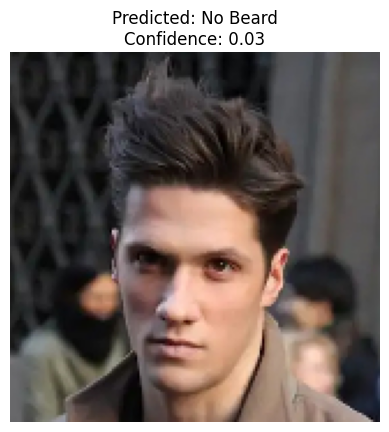

Raw Probability: 0.025218848
Predicted Class: No Beard


In [25]:
import numpy as np
from tensorflow.keras.preprocessing import image
import matplotlib.pyplot as plt
IMG_SIZE = 160
class_names = ['No Beard', 'Beard']
img_path = "/content/Beard or No Beared/Test/No Beard/9.jpg"   # put your image path here

img = image.load_img(img_path, target_size=(IMG_SIZE, IMG_SIZE))
img_array = image.img_to_array(img)
img_array = np.expand_dims(img_array, axis=0) / 255.0
prediction = model.predict(img_array)

probability = prediction[0][0]

if probability >= 0.5:
    predicted_class = class_names[1]
else:
    predicted_class = class_names[0]

plt.imshow(img)
plt.title(f"Predicted: {predicted_class}\nConfidence: {probability:.2f}")
plt.axis("off")
plt.show()
print("Raw Probability:", probability)
print("Predicted Class:", predicted_class)

### Dataset and execution notes
- Update dataset paths to match the folders available in your environment before running.
- The original CNN architecture and training workflow have been retained.
- Results depend on dataset quality, class balance, folder order, and training configuration.